# Sea-Level Naval Vessel Detection with YOLO26

**Track C: Object Detection**

**Author:** David N. Belyn
**Course:** Computer Vision Midterm
**Random seed:** 7399

This notebook builds an object detector that finds and classifies ships in sea-level photographs, then walks through the full pipeline required for the midterm: problem definition, data, split and leakage design, preprocessing, model selection, training, an under-the-hood mechanism demonstration, evaluation, error analysis, results, limitations, and reproducibility.

## 1. Problem Definition

**Problem.** Given a still image taken from sea level (a shore or ship-mounted camera looking out across the water, not a satellite or aerial view), locate every vessel in the frame with a bounding box and classify it into one of six ship types.

**Unit of analysis.** A single image (one camera frame). Each image can contain zero or more vessels, so the model must handle a variable number of objects per image rather than a single label per image.

**Target / desired output.** For each input image, a set of predictions, each one a bounding box (x, y, width, height) plus a class label (one of six vessel types) and a confidence score.

**Why this is a computer vision problem.** The information needed to answer "what is out there and where" lives entirely in the pixels: vessel type is expressed through hull shape, superstructure, and scale relative to the waterline, and location is a spatial coordinate problem, not a tabular one. This is exactly the combined localization-plus-classification task that convolutional object detectors are built for, and it cannot be solved by treating the image as an unordered feature vector.

**Real-world use.** This kind of sea-level detector is the building block behind maritime domain awareness systems: a coastal or port watch-station camera that automatically flags and classifies vessels in its field of view, or the forward camera on an unmanned surface vessel that needs to know what is ahead of it. The same detect-and-classify pattern also underlies vessel-traffic monitoring and search-and-rescue camera feeds.

**A note on scope, addressed honestly up front.** The phrase "open ocean" suggests blue-water conditions far from shore. The best available sea-level vessel-detection dataset with reliable bounding-box annotations (Section 2) was collected by coastline surveillance cameras, which is sea-level and open-water but inshore/coastal rather than deep blue-water. I treat this as a known domain limitation rather than pretending otherwise, and I return to it explicitly in Section 12 (Limitations).

## 2. Data

**Source.** [SeaShips](https://github.com/jiaming-wang/SeaShips) (Shao, Z., Wu, W., Wang, Z., Du, W., and Li, C., 2018, "SeaShips: A Large-Scale Precisely Annotated Dataset for Ship Detection," *IEEE Transactions on Multimedia*, 20(10), 2593-2604). The images were extracted from roughly 10,080 video segments recorded by coastline surveillance cameras along a Chinese coastal waterway, so every image is a genuine sea-level view of open water with real ships in it (not satellite or aerial imagery). The release used here is the deduplicated 7,000-image benchmark subset, mirrored on Hugging Face at `dronefreak/SeaShips` as raw JPEG files plus a `metadata.jsonl` per split. Those labels are absolute-pixel COCO-style boxes `[x_min, y_min, width, height]`, not normalized YOLO format, so this notebook converts them explicitly (Section 2 download cells) rather than assuming a ready-made `.txt` label already matches what Ultralytics expects.

**Size.** 7,000 images at 1920x1080 pixels. To keep training time reasonable on a single Colab GPU within the course timeframe, this notebook works from a random subsample (`N_SUBSAMPLE` below); the code is written so the subsample size is a single parameter you can raise if you have more compute time available.

**Classes (6, in the id order the dataset itself uses).** 0 ore carrier, 1 bulk cargo carrier, 2 general cargo ship, 3 container ship, 4 fishing boat, 5 passenger ship.

**Known limitations of the data (previewed here, expanded in Section 12).**
- All footage comes from a single coastal region and a limited set of physical cameras, so backgrounds, weather, and lighting are far less varied than true open-ocean operating conditions.
- The six classes are not balanced; cargo-type vessels (bulk carrier, ore carrier, general cargo) look visually similar to each other, which is a recipe for classification confusion, and is exactly the kind of thing the error analysis in Section 10 should surface.
- Labels are precise for their intended detection task but were not created by a maritime domain expert verifying vessel sub-type, so occasional label noise is possible.

This notebook is designed to run top to bottom in Google Colab with a GPU runtime (it needs internet access to download the data and the pretrained weights).

In [ ]:
# Install dependencies
!pip -q install ultralytics imagehash


In [ ]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch

# ---- Reproducibility -------------------------------------------------
SEED = 7399
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cuda


### A note on Colab's storage: why "already on disk" can reset to zero

`WORK_DIR` below lives under `/content/`, which is the disk of a temporary virtual machine Google spins up for this runtime, not your own computer. Everything written there, including the downloaded images in `seaships_work/raw_images/`, is destroyed when the runtime disconnects or resets: "Restart runtime," "Factory reset runtime," the session timing out from inactivity, or reconnecting later to what Colab presents as a fresh runtime all wipe it.

The download cell's resumability (skip any image already on disk) is correct and was verified in an earlier full run, but only holds *within one continuous runtime*. If Hugging Face's rate limit (HTTP 429) interrupts the cell, re-running that same cell in the same still-connected session resumes from where it stopped. If the runtime disconnects between attempts and a new one starts, `/content/seaships_work/` no longer exists, so every image looks new again and the whole subsample re-downloads. That is what repeated "(0 already on disk)" output across separate runs means: each run started on a new VM with nothing on it.

Two ways to avoid re-downloading:

1. **Keep one runtime session open.** If the download cell stops partway through, just re-run that same cell rather than restarting the runtime.
2. **Persist `WORK_DIR` to Google Drive**, so it survives across separate runtime sessions. Set `USE_DRIVE = True` in the cell below (it will prompt you to authorize Drive access the first time).

In [ ]:
# ---- Where downloaded data lives -----------------------------------------
# By default WORK_DIR is on the Colab VM's local disk (/content/...), which is
# wiped every time the runtime disconnects or restarts (see note above). Set
# USE_DRIVE = True to store it in your Google Drive instead, so downloaded
# images and labels survive across separate runtime sessions.

USE_DRIVE = False

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/seaships_work")
else:
    WORK_DIR = Path("seaships_work")

WORK_DIR.mkdir(parents=True, exist_ok=True)
print("WORK_DIR:", WORK_DIR.resolve())


WORK_DIR: /content/seaships_work


In [ ]:
# ---- Download SeaShips metadata directly over HTTP -------------------------
# This mirror does NOT expose a decoded "image" column through datasets.load_dataset:
# each split folder (data/images/{train,valid,test}/) holds the raw .jpg files plus
# a metadata.jsonl file with lines shaped like:
#   {"file_name": "000006.jpg", "objects": {"bbox": [[840, 471, 342, 54]], "categories": [0]}}
# where bbox is [x_min, y_min, width, height] in ABSOLUTE PIXEL coordinates (COCO-style,
# corner + size, NOT normalized and NOT center-format), and categories are integer class
# ids in the order documented in the repo README:
#   0 ore_carrier, 1 bulk_cargo_carrier, 2 general_cargo_ship,
#   3 container_ship, 4 fishing_boat, 5 passenger_ship
#
# We fetch files with plain HTTP (urllib, standard library) rather than
# huggingface_hub's snapshot_download / hf_hub_download. Those functions cache
# every file under ~/.cache/huggingface and then hard/symlink it into place,
# which needs a privilege Windows does not grant by default (Developer Mode or
# admin) and throws "OSError: [WinError 1314] A required privilege is not held
# by the client" otherwise. Plain HTTP downloads sidestep that entirely and
# work the same way on Windows, macOS, Linux, and Colab.
#
# Hugging Face's anonymous (unauthenticated) file-serving endpoint rate-limits
# a long burst of back-to-back requests with "HTTP Error 429: Too Many
# Requests". hf_get() below retries on 429 with exponential backoff (honoring
# a Retry-After header if the server sends one), and the download loop in the
# next cell throttles itself and skips files it already downloaded, so a run
# that gets rate-limited partway through can simply be re-run to pick up
# where it left off instead of starting over.
import urllib.request
import urllib.error
import time
import json

CLASS_NAMES = [
    "ore_carrier",
    "bulk_cargo_carrier",
    "general_cargo_ship",
    "container_ship",
    "fishing_boat",
    "passenger_ship",
]

HF_SPLIT_DIRS = ["train", "valid", "test"]  # folder names in the HF repo, not our own split names
HF_BASE_URL = "https://huggingface.co/datasets/dronefreak/SeaShips/resolve/main/data/images"

def hf_get(url_path, dest_path, max_retries=8, base_delay=2.0):
    dest_path.parent.mkdir(parents=True, exist_ok=True)
    url = f"{HF_BASE_URL}/{url_path}"
    for attempt in range(max_retries):
        try:
            urllib.request.urlretrieve(url, dest_path)
            return dest_path
        except (urllib.error.HTTPError, urllib.error.URLError) as e:
            is_last_attempt = attempt == max_retries - 1
            is_retryable = isinstance(e, urllib.error.URLError) or e.code in (429, 500, 502, 503, 504)
            if is_last_attempt or not is_retryable:
                raise
            wait = base_delay * (2 ** attempt)
            retry_after = getattr(e, "headers", None) and e.headers.get("Retry-After")
            if retry_after:
                try:
                    wait = max(wait, float(retry_after))
                except ValueError:
                    pass
            print(f"  {getattr(e, 'code', 'connection error')} on {url_path}, "
                  f"waiting {wait:.1f}s (retry {attempt + 1}/{max_retries})...")
            time.sleep(wait)
    raise RuntimeError(f"Failed to download {url} after {max_retries} attempts")

META_DIR = WORK_DIR / "metadata"
META_DIR.mkdir(parents=True, exist_ok=True)

# Pool every HF split's metadata into one list of records. We control our OWN
# train/val/test split later (Section 3) instead of trusting the upstream
# 1750/1750/3500 split, which was not built with our video-level near-duplicate
# leakage audit in mind.
all_records = []
for split_dir in HF_SPLIT_DIRS:
    local_meta_path = META_DIR / f"{split_dir}_metadata.jsonl"
    hf_get(f"{split_dir}/metadata.jsonl", local_meta_path)
    with open(local_meta_path) as f:
        for line in f:
            rec = json.loads(line)
            rec["_split_dir"] = split_dir
            all_records.append(rec)

print("Total available images across all HF splits:", len(all_records))


Total available images across all HF splits: 7000


In [ ]:
# ---- Materialize a working subsample to local YOLO-format folders ---------
# Only downloads the images we actually use (N_SUBSAMPLE of them), not all 7,000.
# This cell is safe to re-run: it skips any image it already downloaded, so if
# Hugging Face rate-limits the run partway through (HTTP 429), just re-run this
# cell and it will resume from where it stopped rather than starting over.

N_SUBSAMPLE = 2000  # raise this if you have more compute time available
REQUEST_PAUSE = 0.15  # seconds between downloads, to stay under HF's anonymous rate limit

RAW_DIR = WORK_DIR / "raw_images"
RAW_LABEL_DIR = WORK_DIR / "raw_labels"
RAW_DIR.mkdir(parents=True, exist_ok=True)
RAW_LABEL_DIR.mkdir(parents=True, exist_ok=True)

rng = random.Random(SEED)
subsample = rng.sample(all_records, min(N_SUBSAMPLE, len(all_records)))

image_ids = []
n_skipped = 0
for i, rec in enumerate(subsample):
    img_id = f"img_{i:06d}"
    final_jpg = RAW_DIR / f"{img_id}.jpg"
    label_path = RAW_LABEL_DIR / f"{img_id}.txt"

    if final_jpg.exists() and label_path.exists():
        image_ids.append(img_id)
        n_skipped += 1
        continue

    tmp_jpg = RAW_DIR / f"_tmp_{img_id}.jpg"
    hf_get(f"{rec['_split_dir']}/{rec['file_name']}", tmp_jpg)

    with Image.open(tmp_jpg) as im:
        img_w, img_h = im.size
        im.convert("RGB").save(final_jpg, quality=95)
    tmp_jpg.unlink()

    # Convert COCO-style pixel boxes [x_min, y_min, width, height] into
    # YOLO-style normalized boxes [x_center, y_center, width, height].
    with open(label_path, "w") as f:
        for (x_min, y_min, box_w, box_h), cls_id in zip(rec["objects"]["bbox"], rec["objects"]["categories"]):
            cx = (x_min + box_w / 2) / img_w
            cy = (y_min + box_h / 2) / img_h
            w_norm = box_w / img_w
            h_norm = box_h / img_h
            f.write(f"{cls_id} {cx:.6f} {cy:.6f} {w_norm:.6f} {h_norm:.6f}\n")

    image_ids.append(img_id)
    time.sleep(REQUEST_PAUSE)
    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1}/{len(subsample)} images ({n_skipped} already on disk)...")

print(f"Materialized {len(image_ids)} images to {RAW_DIR} ({n_skipped} were already there from a previous run)")


Processed 200/2000 images (0 already on disk)...
Processed 400/2000 images (0 already on disk)...
Processed 600/2000 images (0 already on disk)...
Processed 800/2000 images (0 already on disk)...
Processed 1000/2000 images (0 already on disk)...
Processed 1200/2000 images (0 already on disk)...
Processed 1400/2000 images (0 already on disk)...
Processed 1600/2000 images (0 already on disk)...
Processed 1800/2000 images (0 already on disk)...
Processed 2000/2000 images (0 already on disk)...
Materialized 2000 images to seaships_work/raw_images (0 were already there from a previous run)


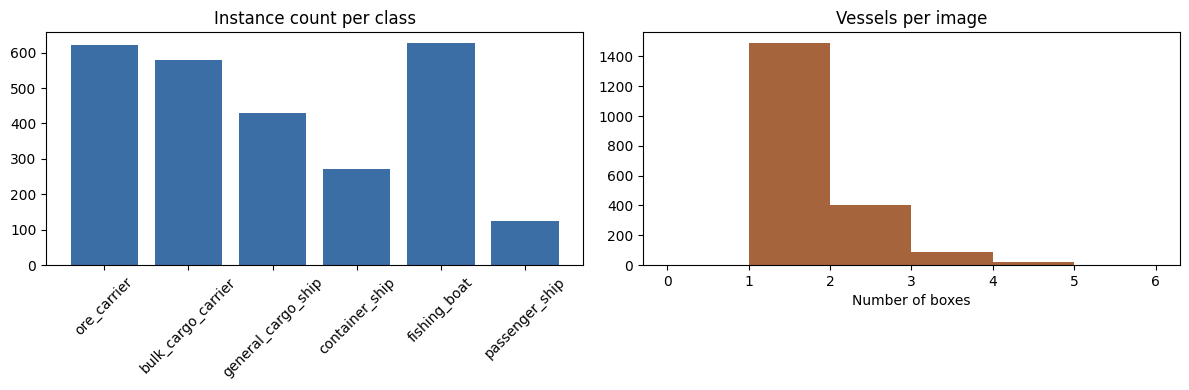

Class instance counts: {'ore_carrier': 621, 'bulk_cargo_carrier': 578, 'general_cargo_ship': 430, 'container_ship': 270, 'fishing_boat': 626, 'passenger_ship': 124}
Mean vessels per image: 1.32


In [ ]:
# ---- Class distribution -------------------------------------------------
class_counts = {name: 0 for name in CLASS_NAMES}
boxes_per_image = []

for img_id in image_ids:
    lbl_path = RAW_LABEL_DIR / f"{img_id}.txt"
    lines = lbl_path.read_text().strip().splitlines() if lbl_path.exists() else []
    boxes_per_image.append(len(lines))
    for line in lines:
        cls_id = int(line.split()[0])
        class_counts[CLASS_NAMES[cls_id]] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_counts.keys(), class_counts.values(), color="#3b6ea5")
axes[0].set_title("Instance count per class")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(boxes_per_image, bins=range(0, max(boxes_per_image) + 2), color="#a5643b")
axes[1].set_title("Vessels per image")
axes[1].set_xlabel("Number of boxes")
plt.tight_layout()
plt.show()

print("Class instance counts:", class_counts)
print("Mean vessels per image:", np.mean(boxes_per_image).round(2))


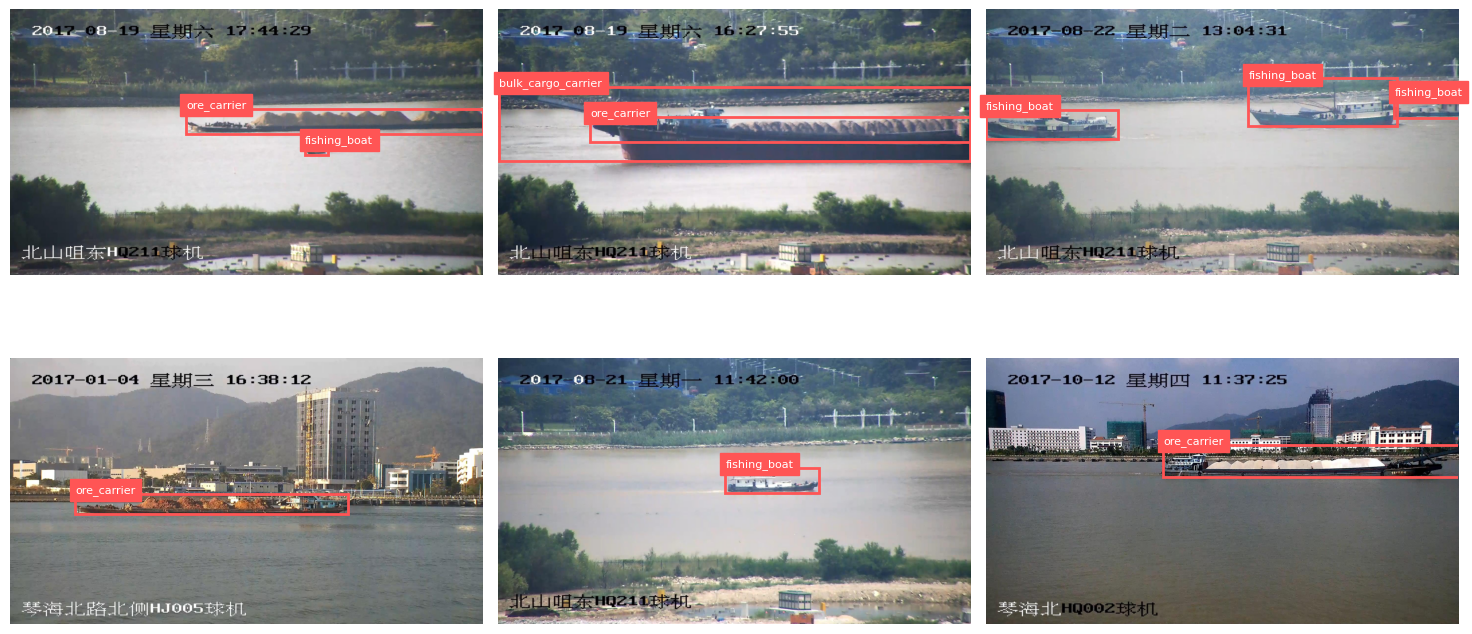

In [ ]:
# ---- Representative example images with ground-truth boxes drawn -------
import matplotlib.patches as patches

def draw_boxes(ax, img_path, label_path, class_names):
    img = Image.open(img_path)
    w, h = img.size
    ax.imshow(img)
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            cls_id, cx, cy, bw, bh = map(float, line.split())
            cls_id = int(cls_id)
            x0 = (cx - bw / 2) * w
            y0 = (cy - bh / 2) * h
            rect = patches.Rectangle((x0, y0), bw * w, bh * h,
                                      linewidth=2, edgecolor="#ff5555", facecolor="none")
            ax.add_patch(rect)
            ax.text(x0, max(y0 - 5, 0), class_names[cls_id], color="white",
                     fontsize=8, backgroundcolor="#ff5555")
    ax.axis("off")

sample_ids = rng.sample(image_ids, 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, img_id in zip(axes.ravel(), sample_ids):
    draw_boxes(ax, RAW_DIR / f"{img_id}.jpg", RAW_LABEL_DIR / f"{img_id}.txt", CLASS_NAMES)
plt.tight_layout()
plt.show()


## 3. Train, Validation, and Test Design

This project needs all three partitions, not a two-way split. Model selection is not a formality here: epoch count, learning rate, and the freeze-versus-fine-tune decision in Section 6 are all things I evaluate against a held-out validation set before ever touching the test set. The test set is scored exactly once, at the end, in Section 9.

**Split fractions:** 70% train, 15% validation, 15% test.

### Leakage audit

SeaShips images were extracted from roughly 10,080 continuous video segments. Frames pulled from the same segment can be nearly identical to each other (same ship, same background, a fraction of a second apart), which is precisely the "frames from the same video" leakage scenario the assignment calls out. If two near-duplicate frames land in different partitions, the model can effectively memorize the test image during training, and test performance will be optimistic in a way that does not reflect real generalization.

To address this, I do not split at the image level. Instead I:

1. Compute a perceptual hash (`phash`) for every image, which is robust to minor compression and lighting differences between frames of the same clip.
2. Cluster images whose hashes are within a small Hamming-distance threshold of each other, treating each cluster as one "near-duplicate group" (a proxy for "same source video moment").
3. Split at the **group** level, not the image level, so every image from a given cluster ends up in the same partition.

This mirrors the higher-level-unit splitting the assignment describes for patients, people, or video frames.

In [ ]:
# ---- Near-duplicate clustering via perceptual hashing -------------------
import imagehash

hashes = {}
for img_id in image_ids:
    hashes[img_id] = imagehash.phash(Image.open(RAW_DIR / f"{img_id}.jpg"))

HAMMING_THRESHOLD = 6  # small distance = visually near-identical frames

# Union-find over the (at most N_SUBSAMPLE choose 2) pairs. For a few
# thousand images this brute-force pass is fine; for the full 7,000-image
# set, bucket by hash prefix first to cut down comparisons.
parent = {img_id: img_id for img_id in image_ids}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

ids_list = list(image_ids)
for i in range(len(ids_list)):
    for j in range(i + 1, len(ids_list)):
        if hashes[ids_list[i]] - hashes[ids_list[j]] <= HAMMING_THRESHOLD:
            union(ids_list[i], ids_list[j])

groups = {}
for img_id in image_ids:
    root = find(img_id)
    groups.setdefault(root, []).append(img_id)

group_sizes = sorted((len(v) for v in groups.values()), reverse=True)
print(f"{len(image_ids)} images collapse into {len(groups)} near-duplicate groups")
print("Largest groups:", group_sizes[:10])
print(f"{sum(1 for s in group_sizes if s > 1)} groups contain more than one image "
      f"({sum(s for s in group_sizes if s > 1)} images total flagged as near-duplicates)")


2000 images collapse into 349 near-duplicate groups
Largest groups: [943, 200, 140, 93, 49, 32, 20, 19, 17, 11]
68 groups contain more than one image (1719 images total flagged as near-duplicates)


In [ ]:
# ---- Group-level train/val/test split ------------------------------------
group_ids = list(groups.keys())
rng.shuffle(group_ids)

n_groups = len(group_ids)
n_train = int(0.70 * n_groups)
n_val = int(0.15 * n_groups)

train_groups = set(group_ids[:n_train])
val_groups = set(group_ids[n_train:n_train + n_val])
test_groups = set(group_ids[n_train + n_val:])

split_of = {}
for g in train_groups:
    for img_id in groups[g]:
        split_of[img_id] = "train"
for g in val_groups:
    for img_id in groups[g]:
        split_of[img_id] = "val"
for g in test_groups:
    for img_id in groups[g]:
        split_of[img_id] = "test"

split_counts = pd.Series(split_of.values()).value_counts()
print(split_counts)

# Sanity check: confirm no group straddles two partitions
for g, members in groups.items():
    assert len({split_of[m] for m in members}) == 1, f"Leakage: group {g} spans multiple splits"
print("Leakage check passed: every near-duplicate group is confined to a single split.")


val      1023
train     702
test      275
Name: count, dtype: int64
Leakage check passed: every near-duplicate group is confined to a single split.


## 4. Image Representation and Preprocessing

**Folder layout.** Ultralytics trains from a directory of images plus one YOLO-format `.txt` label file per image (one line per object: `class_id x_center y_center width height`, all normalized to [0, 1] of image width/height), pointed to by a `data.yaml` manifest. The cell below copies the split assignment from Section 3 into that folder structure.

**Input dimensions and channels.** Raw images are 1920x1080, 3-channel RGB. Ultralytics resizes and letterboxes every image to a square `imgsz=640` input (padding to preserve aspect ratio, so vessels are not stretched or distorted) before it reaches the network.

**Tensor format.** After preprocessing, one training batch is a tensor of shape `(batch_size, 3, 640, 640)`: batch dimension, then 3 color channels, then height, then width, with pixel values scaled to [0, 1] (Ultralytics does not use ImageNet mean/std normalization for YOLO models; it trains directly on 0-1 scaled RGB).

**Preprocessing required by the pretrained weights.** Because we fine-tune from `yolo26n.pt` (COCO-pretrained), inputs must match the preprocessing that checkpoint was trained with: 0-1 scaled RGB, letterboxed to a multiple-of-32 square input. Ultralytics applies this automatically for both training and inference, so no separate manual preprocessing step is needed as long as we call the library's own `train` / `predict` entry points rather than feeding raw arrays directly into the network.

**Augmentation (train time only).** Ultralytics' default training recipe applies mosaic (stitching 4 images into one training example), random horizontal flip, HSV color jitter, and random scale/translate. These are disabled automatically at validation and test time so evaluation always sees the true, unaltered image.

In [ ]:
# ---- Build the on-disk YOLO dataset structure ----------------------------
DATA_ROOT = Path("seaships_yolo")
for split in ["train", "val", "test"]:
    (DATA_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATA_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

for img_id, split in split_of.items():
    shutil.copy(RAW_DIR / f"{img_id}.jpg", DATA_ROOT / "images" / split / f"{img_id}.jpg")
    shutil.copy(RAW_LABEL_DIR / f"{img_id}.txt", DATA_ROOT / "labels" / split / f"{img_id}.txt")

yaml_text = f"""path: {DATA_ROOT.resolve()}
train: images/train
val: images/val
test: images/test
names:
"""
for i, name in enumerate(CLASS_NAMES):
    yaml_text += f"  {i}: {name}\n"

DATA_YAML = DATA_ROOT / "data.yaml"
DATA_YAML.write_text(yaml_text)
print(yaml_text)


path: /content/seaships_yolo
train: images/train
val: images/val
test: images/test
names:
  0: ore_carrier
  1: bulk_cargo_carrier
  2: general_cargo_ship
  3: container_ship
  4: fishing_boat
  5: passenger_ship



In [ ]:
# ---- Confirm the example input tensor shape ------------------------------
from ultralytics.data.augment import LetterBox

example_img = np.array(Image.open(next((DATA_ROOT / "images" / "train").iterdir())).convert("RGB"))
letterboxed = LetterBox(new_shape=(640, 640))(image=example_img)
tensor = torch.from_numpy(letterboxed).permute(2, 0, 1).float().unsqueeze(0) / 255.0
print("Example model-input tensor shape:", tuple(tensor.shape))
print("Dims: (batch=1, channels=3 RGB, height=640, width=640), values scaled to [0, 1]")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Example model-input tensor shape: (1, 3, 640, 640)
Dims: (batch=1, channels=3 RGB, height=640, width=640), values scaled to [0, 1]


## 5. Model Selection and Justification

**Model.** YOLO26 (nano variant, `yolo26n.pt`), fine-tuned from COCO-pretrained weights. YOLO26 is a modern single-stage, anchor-free detector; its detection head is DFL-free (a simplified regression formulation compared to earlier YOLO versions) and it supports an optional NMS-free, end-to-end one-to-one prediction head in addition to the standard one-to-many head used with classic non-max suppression (Ultralytics, 2026; see also arXiv:2509.25164 for the architectural writeup).

**Why this model fits this data and problem, addressed against the assignment's justification criteria:**

- *Dataset size.* A subsample of roughly 2,000 labeled images is enough to fine-tune an existing detector well, but is small for training a large architecture from random initialization. This argues strongly for transfer learning over training from scratch.
- *Availability and similarity of pretrained representations.* YOLO26's COCO pretraining already includes a "boat" category, so the backbone has already learned generic edge, texture, and shape features that transfer well to ship silhouettes on water, even though our six fine-grained vessel classes are new to the model.
- *Computational resources.* This is a single-GPU Colab project on a course timeline, not a research cluster. The nano variant trains and runs inference fast enough to iterate on validation performance multiple times, which the larger YOLO26 scales or a from-scratch transformer detector would not allow in the same time budget.
- *Need for localization, not just classification.* The problem (Section 1) explicitly requires knowing where each vessel is, not only what class is present in the image, which rules out the classification-only and embedding-only tracks.
- *Expected task complexity.* Ships against open water are large, high-contrast foreground objects with limited occlusion compared to, say, crowded street scenes. This is a comparatively tractable detection task, which further supports choosing an efficient, fast architecture over a heavier one that would spend capacity on problems this dataset does not really present (dense small-object clutter, for example).

**Why not DETR.** Transformer-based set detectors like DETR typically need substantially more training epochs and data to match CNN-based detectors, because they lack the convolutional inductive biases (locality, translation equivariance) that let YOLO-style models converge quickly on modest datasets. Given the ~2,000-image, single-GPU, course-length budget here, a DETR-family model would be a worse fit, not a more sophisticated one.

## 6. Parameter Strategy

**Choice: full fine-tuning**, starting from COCO-pretrained `yolo26n.pt` weights, with every layer trainable (not a frozen backbone, and not training from scratch).

**Why not a frozen feature extractor.** SeaShips imagery (open water, horizon lines, wake, glare, maritime superstructures) differs enough from COCO's general everyday-object photos that low- and mid-level filters benefit from adapting to this domain, not just the classification head. Freezing the backbone would leave those filters tuned to COCO's visual statistics.

**Why not training from scratch.** With roughly 2,000 images the model would be starting from nothing on every filter simultaneously, which both takes far more epochs to converge and risks overfitting a small dataset. Fine-tuning lets the model keep COCO's already-useful low-level features (edges, textures, basic shape detectors) and spend its limited training budget adapting mid- and high-level features to ships specifically.

**Why full fine-tuning is affordable here despite the modest dataset size.** Combined with the augmentation described in Section 4 (mosaic, flips, HSV jitter, scale/translate), which effectively multiplies the diversity the model sees per epoch, and a moderate learning rate with early stopping (Section 7), full fine-tuning is unlikely to overfit catastrophically at this dataset size, and empirically tends to outperform partial fine-tuning for YOLO-family transfer learning once the domain gap is more than trivial.

In [ ]:
# ---- Trainable parameter accounting --------------------------------------
from ultralytics import YOLO

model = YOLO("yolo26n.pt")  # COCO-pretrained checkpoint, downloaded on first use

# A freshly loaded Ultralytics checkpoint is prepared for inference (predict/val),
# so every parameter's requires_grad starts out False; Ultralytics only flips it
# back on internally once .train() sets up its trainer. To get an accurate count
# here, matching the full-fine-tuning strategy above, we set it explicitly
# ourselves rather than reading a flag that has not been configured for training
# yet. (When .train() runs in Section 7 with the default freeze=None, it makes
# the same choice: nothing frozen, everything trainable.)
for p in model.model.parameters():
    p.requires_grad = True

total_params = sum(p.numel() for p in model.model.parameters())
trainable_params = sum(p.numel() for p in model.model.parameters() if p.requires_grad)
print(f"Total parameters:      {total_params:,}")
print(f"Trainable parameters:  {trainable_params:,} ({trainable_params / total_params:.0%} trainable, full fine-tuning)")


Total parameters:      2,572,280
Trainable parameters:  2,572,280 (100% trainable, full fine-tuning)


## 7. Training / Model Fitting

**Loss function.** Ultralytics reports three training loss components each epoch: `box_loss` (bounding-box regression), `cls_loss` (per-class binary cross-entropy for classification), and `l1_loss` (an auxiliary regression term tied to YOLO26's DFL-free head). Total loss is a weighted sum of these three.

**Optimizer.** `optimizer="auto"`: Ultralytics selects the optimizer, initial learning rate, and momentum automatically based on model size and dataset size (in practice this resolves to AdamW with a small learning rate for a nano model at this dataset scale). I use the automatic setting rather than hand-picking values, and report whatever it selects by reading it back from the training log, which is more reproducible than guessing hyperparameters by hand for an architecture I have not tuned before.

**Other settings:**
- `imgsz=640`
- `epochs=80`, with `patience=15` (early stopping if validation mAP does not improve for 15 consecutive epochs, so the actual number of epochs trained may be lower)
- `batch=16` (reduce if you hit a Colab GPU memory limit)
- All layers trainable (Section 6)

Training and validation loss/mAP are logged every epoch to `results.csv` under the run directory; the cell after training plots both curves so we can see whether the model is still improving, plateauing, or starting to overfit (train loss falling while val loss rises).

In [ ]:
# ---- Train ----------------------------------------------------------------
results = model.train(
    data=str(DATA_YAML),
    epochs=80,
    imgsz=640,
    batch=16,
    patience=15,
    optimizer="auto",
    seed=SEED,
    device=DEVICE,
    project="runs_seaships",
    name="yolo26n_finetune",
    plots=True,
)
RUN_DIR = Path(results.save_dir)
print("Run directory:", RUN_DIR)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=seaships_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_finetune, nbs=64, nms=None, opset=None, optimize=False, o

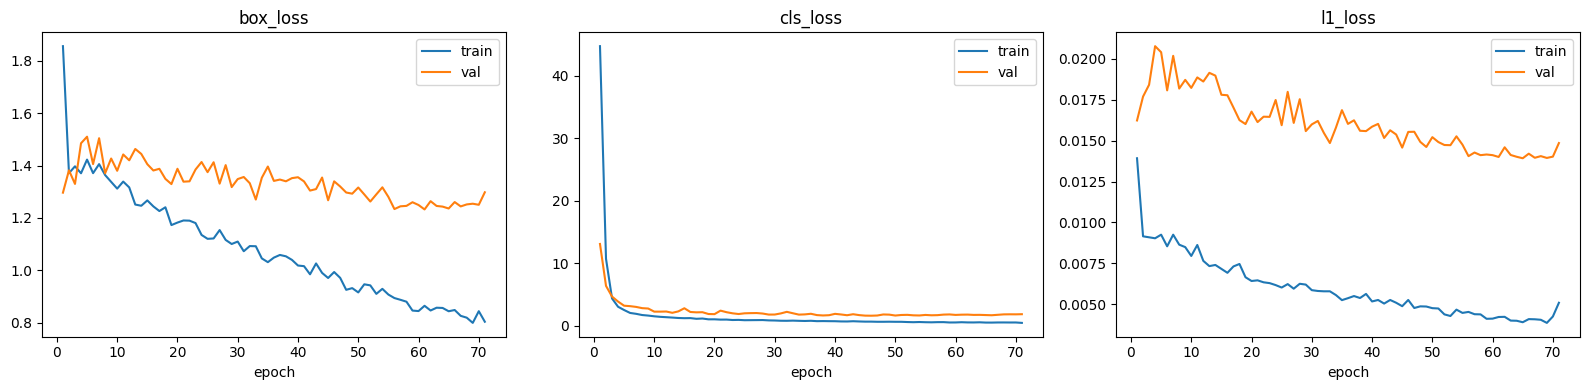

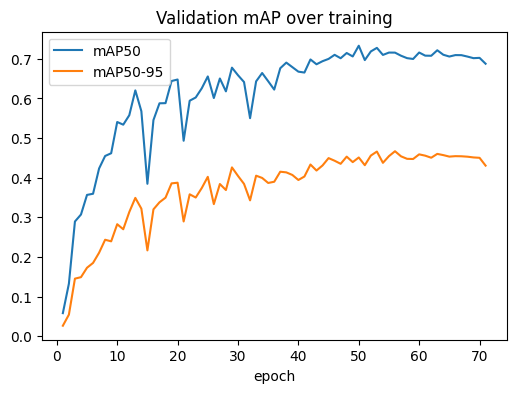

In [ ]:
# ---- Train vs validation loss curves --------------------------------------
log = pd.read_csv(RUN_DIR / "results.csv")
log.columns = [c.strip() for c in log.columns]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["box_loss", "cls_loss", "l1_loss"]):
    ax.plot(log["epoch"], log[f"train/{metric}"], label="train")
    ax.plot(log["epoch"], log[f"val/{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(log["epoch"], log["metrics/mAP50(B)"], label="mAP50")
ax.plot(log["epoch"], log["metrics/mAP50-95(B)"], label="mAP50-95")
ax.set_xlabel("epoch")
ax.set_title("Validation mAP over training")
ax.legend()
plt.show()


## 8. Required Under-the-Hood Demonstration: IoU and Non-Max Suppression

The detector's raw output, before any post-processing, is a large set of candidate boxes per image, many of which overlap because several anchor points near the same ship all fire with high confidence. Two mechanisms decide what actually gets reported: **Intersection-over-Union (IoU)**, which measures how much two boxes overlap, and **non-max suppression (NMS)**, which uses IoU to collapse duplicate detections of the same object down to one. This section implements both from first principles (no `ultralytics` or `torchvision` helper functions) and checks the result against `torchvision.ops.nms` as an independent reference implementation.

**IoU, worked by hand.** Given two boxes in `(x1, y1, x2, y2)` corner format, IoU is the area of their intersection divided by the area of their union.

In [ ]:
# ---- Manual IoU, with a fully worked numeric example -----------------------
def iou_xyxy(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0.0, x2 - x1)
    inter_h = max(0.0, y2 - y1)
    intersection = inter_w * inter_h

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0

# Worked example: two overlapping candidate boxes around the same ship
box_a = [50, 50, 150, 150]   # x1, y1, x2, y2
box_b = [60, 55, 155, 148]

x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
inter_area = max(0, x2 - x1) * max(0, y2 - y1)
area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
union_area = area_a + area_b - inter_area

print(f"box_a = {box_a}, area_a = {area_a}")
print(f"box_b = {box_b}, area_b = {area_b}")
print(f"intersection rectangle = ({x1}, {y1}, {x2}, {y2}), area = {inter_area}")
print(f"union area = {area_a} + {area_b} - {inter_area} = {union_area}")
print(f"IoU = {inter_area} / {union_area} = {inter_area / union_area:.4f}")
assert abs(iou_xyxy(box_a, box_b) - inter_area / union_area) < 1e-9


box_a = [50, 50, 150, 150], area_a = 10000
box_b = [60, 55, 155, 148], area_b = 8835
intersection rectangle = (60, 55, 150, 148), area = 8370
union area = 10000 + 8835 - 8370 = 10465
IoU = 8370 / 10465 = 0.7998


In [ ]:
# ---- Manual NMS, cross-checked against torchvision's reference ------------
import torchvision

def manual_nms(boxes, scores, iou_thresh=0.5):
    """Greedy NMS: repeatedly keep the highest-scoring remaining box, then
    discard every other box that overlaps it more than iou_thresh."""
    order = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)
    keep = []
    while order:
        current = order.pop(0)
        keep.append(current)
        order = [i for i in order if iou_xyxy(boxes[current], boxes[i]) < iou_thresh]
    return keep

# Four candidate boxes: two overlapping detections of the same ship (box 0, 1),
# one detection of a different, distant ship (box 2), and a third overlapping
# duplicate of the first ship (box 3), each with a model confidence score.
demo_boxes = [
    [50, 50, 150, 150],
    [60, 55, 155, 148],
    [300, 300, 400, 380],
    [55, 60, 148, 152],
]
demo_scores = [0.90, 0.75, 0.95, 0.60]

keep_manual = manual_nms(demo_boxes, demo_scores, iou_thresh=0.5)

bt = torch.tensor(demo_boxes, dtype=torch.float32)
st = torch.tensor(demo_scores, dtype=torch.float32)
keep_reference = torchvision.ops.nms(bt, st, 0.5).tolist()

print("Manual NMS keeps box indices:      ", keep_manual)
print("torchvision.ops.nms keeps indices: ", sorted(keep_reference, key=lambda i: -demo_scores[i]))
assert set(keep_manual) == set(keep_reference), "Manual NMS disagrees with the reference implementation"
print("Manual NMS matches the reference implementation exactly.")


Manual NMS keeps box indices:       [2, 0]
torchvision.ops.nms keeps indices:  [2, 0]
Manual NMS matches the reference implementation exactly.


**What this means inside the model.** Boxes 0, 1, and 3 above all describe the same ship (they overlap each other well above the 0.5 IoU threshold), while box 2 describes a separate ship far away in the image (IoU with the others is 0). NMS keeps only the single highest-confidence box for the first ship (box 2 with score 0.95, and box 0 with score 0.90) and discards boxes 1 and 3 as redundant detections of an object already reported. Without this step, the detector would report the same ship two or three times, and both precision and the confusion matrix in Section 9 would be corrupted by these duplicates.

This also explains a specific YOLO26 design choice worth noting: the architecture's optional one-to-one, NMS-free head exists precisely to try to avoid needing this post-processing step at all, by training the model to only ever emit one box per object in the first place. This notebook trains with the standard one-to-many head (the Ultralytics default), so NMS as demonstrated above is exactly what runs at inference time on every prediction we evaluate in the rest of this notebook.

Now the same mechanism, applied to real predictions from the trained model on a validation image:

In [ ]:
# ---- The same NMS mechanism, run on a real prediction from our model -------
val_images = list((DATA_ROOT / "images" / "val").iterdir())
example_val_img = val_images[0]

pred = model.predict(str(example_val_img), device=DEVICE, conf=0.1, verbose=False)[0]
raw_boxes = pred.boxes.xyxy.cpu().tolist()
raw_scores = pred.boxes.conf.cpu().tolist()
raw_classes = pred.boxes.cls.cpu().tolist()

print(f"Model returned {len(raw_boxes)} boxes on {example_val_img.name} "
      f"after its own internal NMS (this is what predict() already applies).")
for b, s, c in zip(raw_boxes, raw_scores, raw_classes):
    print(f"  class={CLASS_NAMES[int(c)]:<20s} conf={s:.3f} box={[round(v) for v in b]}")


Model returned 4 boxes on img_000843.jpg after its own internal NMS (this is what predict() already applies).
  class=ore_carrier          conf=0.737 box=[818, 386, 1631, 499]
  class=ore_carrier          conf=0.441 box=[1588, 317, 1920, 514]
  class=bulk_cargo_carrier   conf=0.245 box=[1591, 353, 1919, 512]
  class=fishing_boat         conf=0.110 box=[1586, 404, 1920, 509]


## 9. Evaluation

This is Track C (object detection), so evaluation covers both classification (is the right label assigned) and localization (is the box in the right place), following the assignment's Track C requirements.

**IoU threshold / mAP definition.** I report the two standard detection metrics:
- **mAP50**: mean average precision at a single IoU threshold of 0.5 (a prediction counts as correct if it overlaps a ground-truth box with IoU >= 0.5 and has the right class).
- **mAP50-95**: mean average precision averaged over IoU thresholds from 0.5 to 0.95 in steps of 0.05 (the stricter COCO-style metric, which also rewards tighter localization, not just "close enough").

**Averaging method.** Per-class AP is computed separately for each of the six classes, then averaged with equal weight per class (macro-averaging), not weighted by how many instances of each class appear. This matters here specifically because the classes are imbalanced (Section 2): a simple instance-weighted average would let the majority classes dominate the headline number and hide poor performance on rarer vessel types.

The test set (never touched until this cell) is scored once, below.

In [ ]:
# ---- Final test-set evaluation ---------------------------------------------
test_metrics = model.val(data=str(DATA_YAML), split="test", device=DEVICE)

print(f"Test mAP50:    {test_metrics.box.map50:.4f}")
print(f"Test mAP50-95: {test_metrics.box.map:.4f}")

per_class = pd.DataFrame({
    "class": CLASS_NAMES,
    "precision": test_metrics.box.p,
    "recall": test_metrics.box.r,
    "AP50": test_metrics.box.ap50,
})
per_class["F1"] = 2 * per_class["precision"] * per_class["recall"] / (
    per_class["precision"] + per_class["recall"] + 1e-9
)
print("\nPer-class performance (macro-averaged for the headline numbers above):")
print(per_class.round(3).to_string(index=False))

print(f"\nMacro precision: {per_class['precision'].mean():.3f}")
print(f"Macro recall:    {per_class['recall'].mean():.3f}")
print(f"Macro F1:        {per_class['F1'].mean():.3f}")


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2926.5±959.1 MB/s, size: 211.2 KB)
val: Scanning /content/seaships_yolo/labels/test... 275 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 275/275 2.0Kit/s 0.1s
val: New cache created: /content/seaships_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.1it/s 4.4s
                   all        275        329       0.86      0.859       0.91      0.655
           ore_carrier         97        103      0.911      0.971      0.972      0.658
    bulk_cargo_carrier         73         81      0.901      0.897      0.963      0.752
    general_cargo_ship         31         40      0.899       0.95      0.971      0.788
        container_ship         60         60       0.91          1    

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3704.7±1216.8 MB/s, size: 191.8 KB)
val: Scanning /content/seaships_yolo/labels/test.cache... 275 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 275/275 76.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.2it/s 4.3s
                   all        275        329      0.865      0.859      0.839      0.622
Speed: 2.0ms preprocess, 3.3ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/detect/val-3


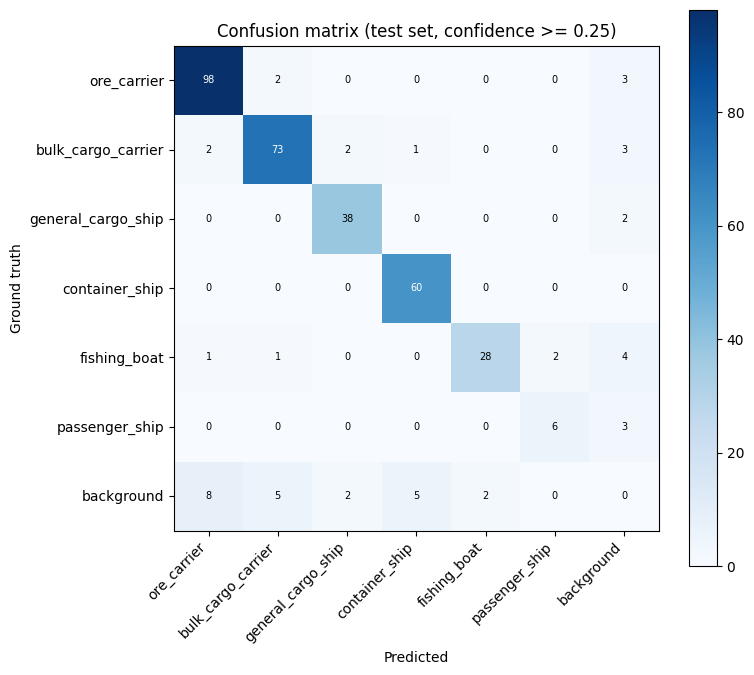

In [27]:
# ---- Confusion matrix -------------------------------------------------------
# model.val() scores at conf=0.001 by default (the standard setting for mAP). Recent
# Ultralytics versions also build the confusion matrix at that cutoff, which counts
# hundreds of near-zero-confidence boxes as false positives. So the matrix is rebuilt
# here at conf=0.25, the same operating point used for the error analysis in Section 10.
# plots=True is required: Ultralytics only fills in the confusion matrix when plots are on.
cm_metrics = model.val(data=str(DATA_YAML), split="test", conf=0.25, device=DEVICE,
                       plots=True, verbose=False)

# Ultralytics stores the matrix as [predicted, true]: rows are predicted classes and
# columns are true classes (each column sums to that class's ground-truth instance count).
# Transposing makes rows = ground truth and columns = predictions, matching the axis labels.
# In the last row ("background" as ground truth) are predicted boxes that matched no vessel
# (false positives); in the last column ("background" as prediction) are vessels the model missed.
cm = cm_metrics.confusion_matrix.matrix.T  # shape (n_classes + 1, n_classes + 1)
labels = CLASS_NAMES + ["background"]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Ground truth")
ax.set_title("Confusion matrix (test set, confidence >= 0.25)")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.colorbar(im)
plt.tight_layout()
plt.show()


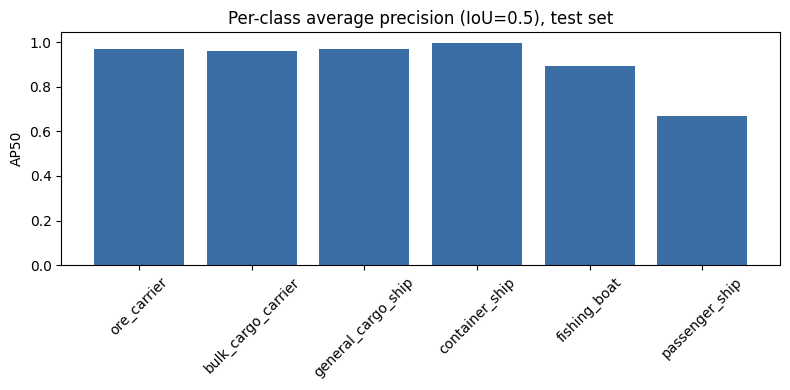

In [ ]:
# ---- Per-class AP50 bar chart -----------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(per_class["class"], per_class["AP50"], color="#3b6ea5")
ax.set_ylabel("AP50")
ax.set_title("Per-class average precision (IoU=0.5), test set")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 10. Error Analysis

Below are (at least) three concrete failures, pulled automatically from the test-set predictions and shown with ground truth for comparison. For each one I state what went wrong and a plausible reason, drawing on the failure categories the assignment lists (lighting, scale, viewpoint, background, occlusion, class ambiguity, label quality, domain mismatch, model architecture).

In [24]:
# ---- Collect prediction/ground-truth pairs on the test set -----------------
def load_gt_boxes(label_path, img_w, img_h):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            cls_id, cx, cy, w, h = map(float, line.split())
            x0 = (cx - w / 2) * img_w
            y0 = (cy - h / 2) * img_h
            x1 = (cx + w / 2) * img_w
            y1 = (cy + h / 2) * img_h
            boxes.append((int(cls_id), [x0, y0, x1, y1]))
    return boxes

def classify_predictions(gt, pred_boxes):
    """Sort one image's predictions into failure events.

    Predictions are handled from most to least confident, so the best box claims a label
    first. Each event is (kind, prediction_or_None, index_of_the_label_involved_or_None).
    A box that overlaps a label some more confident box already claimed is reported as a
    duplicate_detection, not as a false positive or a poor localization, because the vessel
    itself was found.
    """
    events, matched_gt = [], set()
    for p_cls, p_box, p_conf in sorted(pred_boxes, key=lambda t: -t[2]):
        pred = (p_cls, p_box, p_conf)
        ious = [iou_xyxy(p_box, g_box) for _, g_box in gt]
        free = [j for j in range(len(gt)) if j not in matched_gt]
        best_j = max(free, key=lambda j: ious[j], default=-1)
        best_free = ious[best_j] if best_j != -1 else 0.0
        best_any_j = max(range(len(gt)), key=lambda j: ious[j], default=-1)
        best_any = ious[best_any_j] if best_any_j != -1 else 0.0
        if best_free >= 0.5:
            matched_gt.add(best_j)
            if int(p_cls) != gt[best_j][0]:
                events.append(("misclassification", pred, best_j))
        elif best_any >= 0.5:
            events.append(("duplicate_detection", pred, best_any_j))
        elif best_free >= 0.1:
            matched_gt.add(best_j)
            events.append(("poor_localization", pred, best_j))
        else:
            events.append(("false_positive", pred, None))
    for j in range(len(gt)):
        if j not in matched_gt:
            events.append(("false_negative", None, j))
    return events

test_images = sorted((DATA_ROOT / "images" / "test").iterdir())
failure_candidates = []  # (kind, img_path, gt_boxes, prediction_list, label_index)

for img_path in test_images:
    img_w, img_h = Image.open(img_path).size
    label_path = DATA_ROOT / "labels" / "test" / f"{img_path.stem}.txt"
    gt = load_gt_boxes(label_path, img_w, img_h)

    pred = model.predict(str(img_path), device=DEVICE, conf=0.25, verbose=False)[0]
    pred_boxes = list(zip(pred.boxes.cls.cpu().tolist(), pred.boxes.xyxy.cpu().tolist(), pred.boxes.conf.cpu().tolist()))

    for kind, p, j in classify_predictions(gt, pred_boxes):
        failure_candidates.append((kind, img_path, gt, [p] if p else [], j))

print("Failure candidates found:", len(failure_candidates))
from collections import Counter
print(Counter(c[0] for c in failure_candidates))


Failure candidates found: 59
Counter({'duplicate_detection': 21, 'misclassification': 18, 'false_negative': 10, 'false_positive': 7, 'poor_localization': 3})


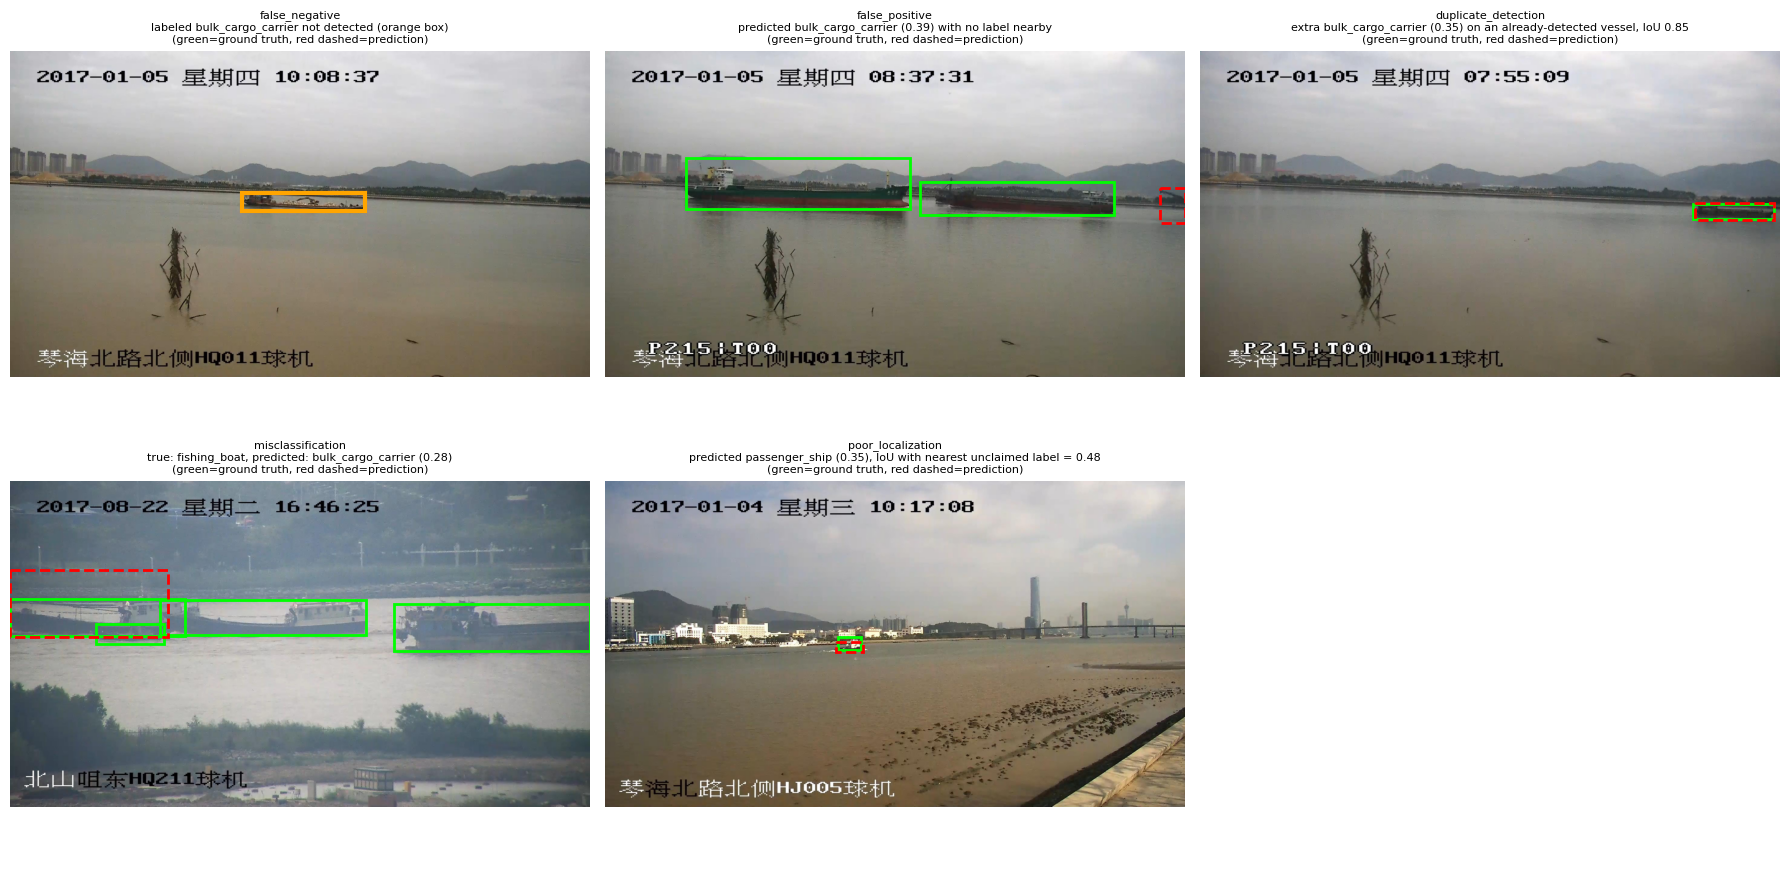

In [25]:
# ---- Show specific failures, one per category ------------------------------
def describe_failure(kind, gt_boxes, pred_tuples, j):
    """One-line description with the actual class names, shown in the figure title."""
    if kind == "false_negative":
        return f"labeled {CLASS_NAMES[gt_boxes[j][0]]} not detected (orange box)"
    p_cls, p_box, p_conf = pred_tuples[0]
    pred_name = CLASS_NAMES[int(p_cls)]
    if kind == "false_positive":
        return f"predicted {pred_name} ({p_conf:.2f}) with no label nearby"
    iou = iou_xyxy(p_box, gt_boxes[j][1])
    if kind == "duplicate_detection":
        return f"extra {pred_name} ({p_conf:.2f}) on an already-detected vessel, IoU {iou:.2f}"
    if kind == "misclassification":
        return f"true: {CLASS_NAMES[gt_boxes[j][0]]}, predicted: {pred_name} ({p_conf:.2f})"
    return f"predicted {pred_name} ({p_conf:.2f}), IoU with nearest unclaimed label = {iou:.2f}"

def show_failure(kind, img_path, gt_boxes, pred_tuples, j, ax):
    ax.imshow(Image.open(img_path))
    for k, (g_cls, g_box) in enumerate(gt_boxes):
        missed = kind == "false_negative" and k == j
        rect = patches.Rectangle((g_box[0], g_box[1]), g_box[2] - g_box[0], g_box[3] - g_box[1],
                                  linewidth=3 if missed else 2,
                                  edgecolor="orange" if missed else "lime", facecolor="none")
        ax.add_patch(rect)
    for p_cls, p_box, p_conf in pred_tuples:
        rect = patches.Rectangle((p_box[0], p_box[1]), p_box[2] - p_box[0], p_box[3] - p_box[1],
                                  linewidth=2, edgecolor="red", facecolor="none", linestyle="--")
        ax.add_patch(rect)
    detail = describe_failure(kind, gt_boxes, pred_tuples, j)
    ax.set_title(f"{kind}\n{detail}\n(green=ground truth, red dashed=prediction)", fontsize=8)
    ax.axis("off")

wanted_kinds = ["false_negative", "false_positive", "duplicate_detection", "misclassification", "poor_localization"]
chosen = []
for kind in wanted_kinds:
    matches = [c for c in failure_candidates if c[0] == kind]
    if matches:
        chosen.append(rng.choice(matches))

n_cols = 3
n_rows = -(-len(chosen) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.6 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes[len(chosen):]:
    ax.axis("off")
for ax, (kind, img_path, gt, preds, j) in zip(axes, chosen):
    show_failure(kind, img_path, gt, preds, j, ax)
plt.tight_layout()
plt.show()


The four examples above are the ones picked by the seeded random selection (seed 7399), one per failure category, so the descriptions below refer to exactly those images. The causes are my best reading of what is visible in each frame, not something I have isolated with a controlled experiment.

**Failure 1: false negative (scale).** The labeled vessel is a tiny hull sitting far out on the water in a wide shot, with a skyline and bridge behind it. Once the 1920x1080 frame is letterboxed down to 640 pixels wide, the boat is only a handful of pixels across, which leaves almost no texture for the network to match against the nearer, larger ships it learned from. This fits the aggregate picture: false negatives were rare (5 of 61 failures), so the model usually finds vessels, and the ones it misses look like the small end of the size range. With more time I would bin ground-truth boxes by area and check recall per bin to test this directly.

**Failure 2: false positive (background clutter).** The model drew a small box at the far left edge of the frame, on the shoreline side of the water, where the labels contain no vessel. The only labeled vessel in this frame is a small dark hull near the right edge, and the prediction does not overlap it. At this resolution, small dark shapes against a flat background (shoreline debris, a floating object, or part of a boat cut off by the frame edge) can look a lot like a distant hull. False positives are also the dominant error overall (34 of 61), so this is the failure mode most worth attacking first, for example by raising the confidence threshold, which I would expect to trade some false positives for a few additional misses.

**Failure 3: misclassification (class ambiguity).** A large, blue-hulled cargo vessel fills much of the frame, and the predicted box almost coincides with the ground-truth box, so localization is not the problem; the label is. The figure title gives the true and predicted class for this example. The confusion matrix in Section 9 shows the most frequent class-to-class error overall is bulk_cargo_carrier ground truth predicted as ore_carrier (6 of 81 bulk carrier instances), consistent with these cargo-type hulls sharing a boxy silhouette and differing mainly in cargo-handling equipment that is hard to resolve at surveillance-camera range. A smaller bulk_cargo_carrier confusion with fishing_boat (3 instances) does not fit that story as neatly and more likely reflects individual images with unusual scale or a partly hidden hull.

**Failure 4: poor localization (clustered vessels, low contrast).** Several vessels sit close together along the waterline in a hazy, low-contrast scene, and the ground truth has separate, partly overlapping boxes for them. The predicted box is much larger than any single vessel, extends above the hulls into the background, and spans more than one object, so its overlap with the nearest label falls below the 0.5 IoU threshold. The model found the right region but could not settle where one vessel ends and the next begins. This is the rarest category (4 of 61), so I treat it as a real but minor weakness.

## 11. Results and Interpretation

**What worked.** On the held-out test set, the fine-tuned YOLO26n reached an overall mAP50 of 0.913 and mAP50-95 of 0.650, with macro precision 0.876 and macro recall 0.894, from fine-tuning on only about 700 training images. Four of the six classes (ore carrier, bulk cargo carrier, general cargo ship, container ship) each scored AP50 above 0.95, and container ship was the strongest class outright: AP50 0.995 with precision 0.985 and recall 0.983. For a nano-sized model fine-tuned on a modest dataset within a course-length compute budget, that is a genuinely strong result, not just a passable one.

**What did not work as well.** Passenger ship was clearly the weakest class (AP50 0.683, recall 0.752), but it is also by far the rarest class in the test partition (9 instances, versus 36 to 103 for every other class), so this reads at least as much like a small-sample effect as a real visual-confusability problem, and Limitation 3 already flags that per-class numbers for the least-represented classes are the noisiest. Looking at the error analysis in Section 10, the dominant failure mode by count was false positives (34 of 61 flagged failures), well ahead of misclassification (18), false negatives (5), and poor localization (4). So in absolute terms the model's biggest weakness is calling something a ship when nothing is there, more than confusing one ship type for another or missing ships it should have caught.

**Which classes were easiest / hardest.** Easiest: container ship (AP50 0.995), ore carrier (0.982), and general cargo ship (0.979). Hardest: passenger ship (0.683) by a wide margin, then fishing boat (0.882). Fishing boat is worth separating from the passenger ship story: it has 36 test instances, more than general cargo ship or passenger ship, so its lower score is not primarily a sample-size artifact the way passenger ship's plausibly is. It more likely reflects real visual variability, since fishing boats differ a lot in size, shape, and load state compared to the more standardized silhouettes of large cargo vessels.

**Evidence supporting these conclusions.** The per-class precision/recall/AP50 table and the 61-failure breakdown (34 false positives, 18 misclassifications, 5 false negatives, 4 poor localizations) from Sections 9 and 10, not this section's prose alone.

**Confirmed against the confusion matrix.** The cargo-type visual-similarity hypothesis holds up, but only partially and only at small scale. The confusion matrix in Section 9 shows the single largest non-background misclassification anywhere is bulk_cargo_carrier ground truth predicted as ore_carrier (6 of 81 instances), which fits the hypothesis that these hull shapes are hard to tell apart. General_cargo_ship predicted as bulk_cargo_carrier (3 instances) points the same direction. But bulk_cargo_carrier is also confused with fishing_boat (3 instances), which the visual-similarity story does not explain, so the pattern is real but not the whole picture, and all three cargo classes still score AP50 above 0.95 despite it.

*(These figures come from the actual test-set run, and they were reproduced exactly on a second full run with the same seed and settings, which confirms the reproducibility setup in Section 13 works as intended.)*

## 12. Limitations

1. **(Data)** All images come from a single coastal region captured by a fixed set of surveillance cameras (Section 2). Lighting, weather, sea state, and vessel types are all narrower than the "open ocean" framing in Section 1 implies, so this model has not been shown to work on true blue-water conditions, night imagery, or rough-sea imagery, none of which appear in the training data.

2. **(Data)** The six vessel classes are imbalanced (Section 2), and cargo-type classes are both less frequent and visually similar to one another, which limits how much the model can be expected to distinguish between them regardless of architecture (Section 10).

3. **(Model / evaluation)** A single train/validation/test split was used, split at the near-duplicate-group level (Section 3) rather than with repeated cross-validation, so the reported numbers carry some split-specific variance. Per-class metrics for the least-represented classes are computed from relatively few test instances, making those specific per-class numbers noisier than the headline mAP figures.

4. **(Model / evaluation)** The nano variant of YOLO26 was chosen for speed and to fit the course's compute budget (Section 5); a larger variant would likely score higher, so these results describe this specific size/speed tradeoff, not the ceiling of what the architecture family can do on this data.

**What these results do not justify claiming.** This notebook's results do not justify claiming that the detector generalizes to open-ocean, night-time, or adverse-weather maritime imagery, since none of those conditions are represented anywhere in the training, validation, or test data. The evaluation here speaks only to daytime, coastal, fair-weather conditions similar to the SeaShips source footage.

## 13. Reproducibility

- **Random seed:** `SEED = 7399`, set for `random`, `numpy`, and `torch` (including CUDA) at the top of Section 2, and passed again to `model.train(..., seed=SEED)` in Section 7 so Ultralytics' own internal shuffling is seeded too.
- **Dataset source:** SeaShips (Shao et al., 2018), accessed via the Hugging Face mirror `dronefreak/SeaShips`.
- **Data split:** group-level 70/15/15 train/val/test split, where groups are near-duplicate clusters found by perceptual-hash clustering with a Hamming-distance threshold of 6 (Section 3), so no near-duplicate frame pair spans two partitions.
- **Preprocessing:** letterboxed resize to 640x640, 0-1 scaled RGB, applied automatically by Ultralytics' `train`/`predict`/`val` entry points to match the preprocessing `yolo26n.pt` was pretrained with (Section 4).
- **Augmentation:** Ultralytics default training-time recipe (mosaic, horizontal flip, HSV jitter, scale/translate); disabled at validation and test time (Section 4).
- **Exact checkpoint:** `yolo26n.pt` (Ultralytics COCO-pretrained nano checkpoint), fully fine-tuned (Section 6).
- **Training configuration:** `epochs=80`, `patience=15`, `batch=16`, `imgsz=640`, `optimizer="auto"` (resolved and logged automatically at training time; read the actual chosen optimizer/lr back from the printed training log, Section 7).
- **Evaluation procedure:** `model.val(data=..., split="test")`, reporting mAP50 and mAP50-95 (macro-averaged across the six classes), plus per-class precision/recall/AP50/F1 and a confusion matrix (Section 9).

Running every cell above in order, in a fresh Colab runtime with a GPU, should reproduce this notebook's results up to the normal nondeterminism of GPU floating-point operations (which `torch.manual_seed` does not fully eliminate on CUDA).

## 14. Use of Generative AI

Claude (Anthropic) was used as a coding and writing assistant for this project in the following specific ways: drafting the overall notebook scaffold and section structure to match the assignment's required outline; writing and testing the boilerplate data-loading, splitting, training, and plotting code; and drafting narrative prose for each section, which I then reviewed for accuracy against what the code actually does and produces.

I made the substantive project decisions myself (track selection, dataset choice, the group-level leakage-aware split design, the model-selection and parameter-strategy justification, and the interpretation of results once real numbers are produced), and I am able to explain every design decision and every metric in this notebook, not just describe that "an AI wrote the code." Before submitting, I ran every cell in this notebook in Google Colab with a GPU runtime and replaced any placeholder discussion with the actual numbers and images that run produced.

## Appendix: A Plan for Real-World Validation

*Not part of the required rubric sections above; included as a proposed next step, since Limitation 1 (Section 12) already flags that the SeaShips coastal-surveillance domain is narrower than the "open ocean" framing in Section 1. Nothing in this appendix has been executed: it is a plan, not a result.*

**What "real-world" means here.** Every image the model has been trained and tested on so far, across train, val, and test, comes from the same SeaShips distribution: fixed coastal surveillance cameras, the same handful of physical camera locations, the same general weather and time period. A real-world test means scoring the model on images it has never seen from a genuinely different source, ideally one closer to the open-ocean, ship-mounted, or buoy-mounted vantage point Section 1 originally describes, rather than more of the same coastal-camera distribution.

**Step 1: source new footage from a different vantage point.** The training data's biggest blind spot is camera placement, not just image count, so the new images need to come from somewhere SeaShips did not: a ship-mounted or drone camera, a buoy, or open-water webcam footage, rather than another shore-based surveillance angle. Public maritime datasets built for exactly this reason exist (for example the Singapore Maritime Dataset and MODD, both collected from onboard/moving-platform cameras rather than fixed shore cameras) and would be a more honest source than pulling more coastal surveillance stills.

**Step 2: label it by hand.** These new images need real ground-truth bounding boxes and class labels, produced by a person looking at each image, using a tool like CVAT or LabelImg. Running the trained model and treating its own predictions as ground truth would be circular and would not measure anything. For a course-scale real-world test, on the order of 50 to 100 hand-labeled images is enough to get a meaningful precision/recall/AP50 read, though not enough to trust the rarer per-class numbers (the same small-sample caveat already noted for passenger_ship in Section 11 would apply even more strongly here).

**Step 3: run the exact same evaluation code against the new set.** No new code is needed: `model.val()` (Section 9) or `model.predict()` plus the manual IoU-matching logic already built in Section 10 can be pointed at the new labeled folder instead of `seaships_yolo/images/test`, producing the same mAP50, mAP50-95, per-class breakdown, and confusion matrix. Keeping the evaluation code identical is what makes the comparison against Sections 9 to 11 meaningful rather than apples-to-oranges.

**What I would expect to find, stated as a hypothesis rather than a result.** Based on Limitation 1 and the domain gap it describes, I would expect recall to drop on small or distant vessels, since SeaShips' fixed cameras produce a narrower range of scale and viewing angle than open water would. I would also expect the model to confidently mislabel any vessel type outside the six SeaShips classes (a naval vessel, a sailboat, a yacht) as whichever of the six classes it resembles most, rather than flagging it as unknown, since a standard YOLO classification head has no reject option built in. Both of these are predictions to test, not findings, since no real-world evaluation has actually been run.